## **EBSD Data Visualization and Microstructural Analysis**

This document provides a concise summary of the six plots we have generated from the EBSD data. Each plot uses different aspects of the raw data to reveal a unique microstructural feature of the sample.


## **Setting up the Environment**

First, we need to import the necessary libraries. We are using `pandas` for data handling, `matplotlib` for plotting, `numpy` for numerical operations, and `scipy` for quaternion-based calculations, which are essential for our advanced plots.


In [33]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from scipy.spatial.transform import Rotation as R

# Setting a consistent font for all plots for better aesthetics.
plt.rcParams['font.family'] = 'DejaVu Sans'

## **Data Loading**

In [ ]:
file_path = "ebsd.txt"

with open(file_path, 'r') as file:
    lines = file.readlines()

# We are parsing the header to extract the grid dimensions and column names.
header_info = {line.split(":")[0].strip().replace('# ', ''): line.split(":")[1].strip() for line in lines if line.startswith("# ") and ":" in line and not line.startswith('# COLUMN')}

NCOLS_ODD = int(header_info.get('NCOLS_ODD', 0))
NCOLS_EVEN = int(header_info.get('NCOLS_EVEN', 0))
NROWS = int(header_info.get('NROWS', 0))

header_end_index = None
column_headers_line = None
for i, line in enumerate(lines):
    if line.strip() == "# HEADER: End":
        header_end_index = i
    if line.startswith("# COLUMN_HEADERS:"):
        column_headers_line = line

if header_end_index is None or column_headers_line is None:
    raise ValueError("Could not find required header information.")

column_headers = column_headers_line.split(":")[1].strip().split(",")
column_headers = [header.strip() for header in column_headers]

data_string = "".join(lines[header_end_index+1:])
df = pd.read_csv(io.StringIO(data_string), sep='\s+', names=column_headers)

print("Data loaded successfully. We are now plotting the microstructural maps.")    

Data loaded successfully. We are now plotting the microstructural maps.


## **Reconstructed SEM Image**
**Input**: The SEM (Scanning Electron Microscopy) signal from the raw data.

**Output**: A grayscale image that visually represents the sample's surface.

**Significance**: This plot provides a qualitative overview of the sample's surface topography and can highlight physical features like scratches, pores, or contamination that may affect the EBSD signal.



We are plotting the reconstructed SEM image to visualize the surface.


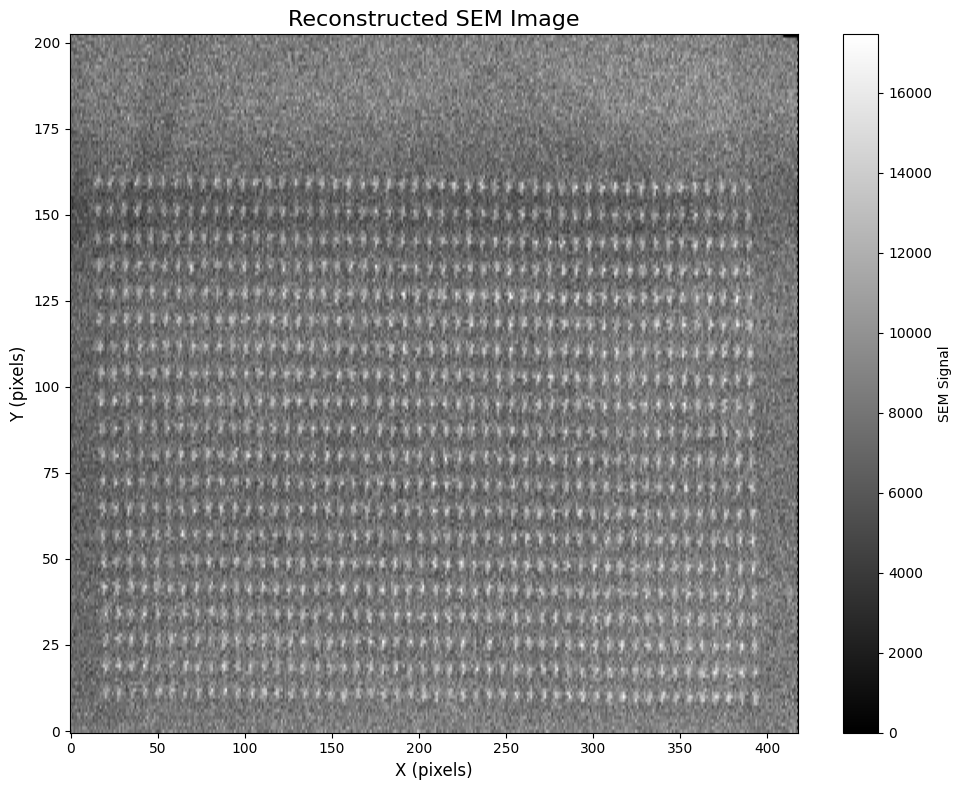

Plot saved as sem_image.png


In [41]:
def plot_from_grid_data(df, column, title, cmap, filename, NCOLS_ODD, NCOLS_EVEN, NROWS):
    """
    We are defining a reusable function to plot 2D images from the 1D grid data.
    This function handles the conversion from the file's list format to a 2D numpy array
    that can be easily plotted. It also adds a colorbar and saves the plot.
    """
    data_list = df[column].tolist()
    data_array = np.zeros((NROWS, NCOLS_ODD), dtype=float)

    data_idx = 0
    for r in range(NROWS):
        num_cols = NCOLS_ODD if r % 2 == 0 else NCOLS_EVEN
        for c in range(num_cols):
            if c < NCOLS_ODD and data_idx < len(data_list):
                data_array[r, c] = data_list[data_idx]
            data_idx += 1
    
    plt.figure(figsize=(10, 8))
    plt.imshow(data_array, cmap=cmap, origin='lower', aspect='auto')
    plt.title(title, fontsize=16)
    plt.xlabel('X (pixels)', fontsize=12)
    plt.ylabel('Y (pixels)', fontsize=12)
    plt.colorbar(label=f'{column} Signal', orientation='vertical')
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()
    print(f"Plot saved as {filename}")


# 1. Reconstructed SEM Image
print("We are plotting the reconstructed SEM image to visualize the surface.")
plot_from_grid_data(df, 'SEM', 'Reconstructed SEM Image', cm.gray, 'sem_image.png', NCOLS_ODD, NCOLS_EVEN, NROWS)


## **2. Grain Boundary Map**
**Input**: The IQ (Image Quality) values.

**Output**: A grayscale or colorized map where dark regions indicate low IQ.

**Significance**: Since grain boundaries are areas of high crystallographic disorder, they produce a low IQ signal. This plot effectively visualizes the grain size, shape, and overall microstructure of the sample.

We are plotting the Grain Boundary Map, which highlights grain shapes and boundaries.


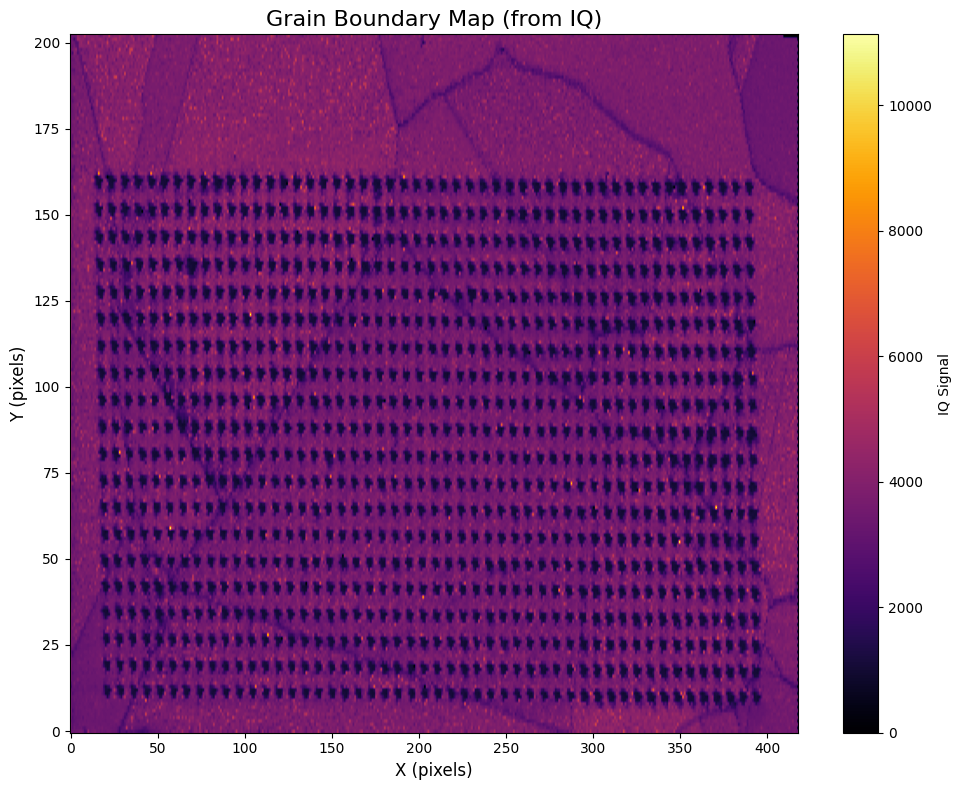

Plot saved as grain_boundary_map.png


In [36]:
# 2. Grain Boundary Map (using IQ)
print("We are plotting the Grain Boundary Map, which highlights grain shapes and boundaries.")
plot_from_grid_data(df, 'IQ', 'Grain Boundary Map (from IQ)', cm.inferno, 'grain_boundary_map.png', NCOLS_ODD, NCOLS_EVEN, NROWS)

## **3. Phase Map**
**Input**: The Phase index values.

**Output**: A map where each phase is assigned a distinct color.

**Significance**: This is a crucial plot for multi-phase materials. It clearly shows the spatial distribution and morphology of each phase within the scanned area, which is vital for understanding phase transformations and material properties.

We are plotting the Phase Map to show the distribution of materials.


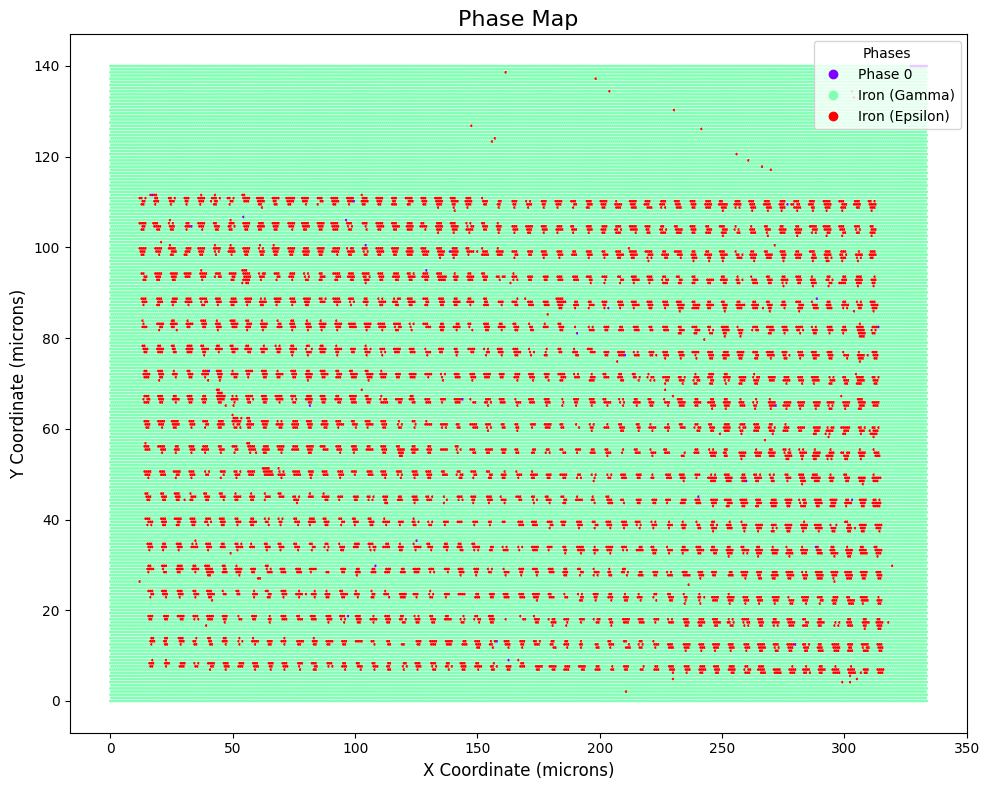

Plot saved as phase_map.png


In [37]:
# 3. Phase Map
print("We are plotting the Phase Map to show the distribution of materials.")
plt.figure(figsize=(10, 8))
scatter = plt.scatter(df['x'], df['y'], c=df['Phase index'], cmap='rainbow', s=1)

unique_phases = sorted(df['Phase index'].unique())
phase_names = {1: 'Iron (Gamma)', 2: 'Iron (Epsilon)'} 

plt.title('Phase Map', fontsize=16)
plt.xlabel('X Coordinate (microns)', fontsize=12)
plt.ylabel('Y Coordinate (microns)', fontsize=12)

handles, _ = scatter.legend_elements()
plt.legend(handles, [phase_names.get(p, f'Phase {p}') for p in unique_phases], title="Phases")

plt.tight_layout()
plt.savefig('phase_map.png')
plt.show()
print("Plot saved as phase_map.png")

## **4. EBSD Orientation Map**
**Input**: The three Euler angles (phi1, PHI, phi2).

**Output**: A color map where the color of each pixel corresponds to its crystallographic orientation.

**Significance**: This is the primary output of EBSD. It reveals the crystallographic texture of the material, showing how grains are oriented relative to each other. Grains with similar colors have similar orientations.


We are plotting the EBSD Orientation Map, the core of the analysis, to show crystal orientations.


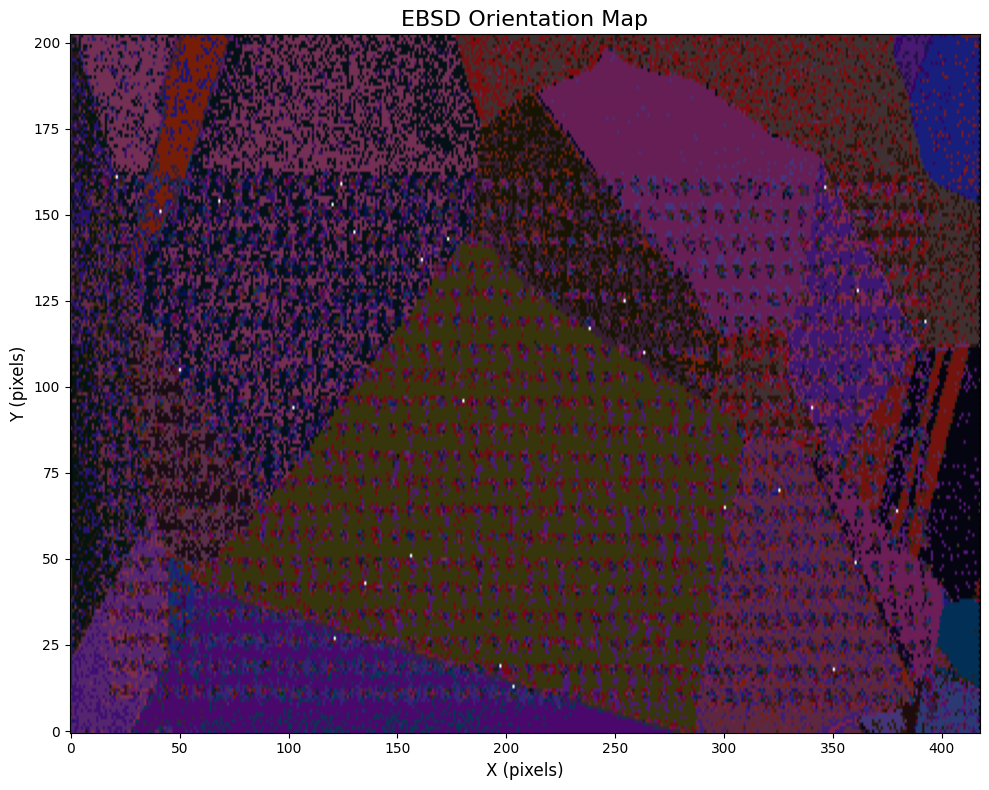

Plot saved as ebsd_orientation_map.png


In [38]:
def plot_ebsd_orientation_map(df, NCOLS_ODD, NCOLS_EVEN, NROWS):
    """
    We are plotting the EBSD Orientation Map. The colors here are derived from the
    Euler angles (phi1, PHI, phi2) to represent the crystallographic orientation of each grain.
    A simplified color scheme is used to visualize the texture of the sample.
    """
    norm_phi1 = Normalize(vmin=df['phi1'].min(), vmax=df['phi1'].max())
    norm_PHI = Normalize(vmin=df['PHI'].min(), vmax=df['PHI'].max())
    norm_phi2 = Normalize(vmin=df['phi2'].min(), vmax=df['phi2'].max())

    colors = np.array([
        [norm_phi1(p1), norm_PHI(p2), norm_phi2(p3)]
        for p1, p2, p3 in zip(df['phi1'], df['PHI'], df['phi2'])
    ])
    
    data_idx = 0
    color_map_array = np.zeros((NROWS, NCOLS_ODD, 3), dtype=float)
    
    for r in range(NROWS):
        num_cols = NCOLS_ODD if r % 2 == 0 else NCOLS_EVEN
        for c in range(num_cols):
            if c < NCOLS_ODD and data_idx < len(colors):
                color_map_array[r, c, :] = colors[data_idx]
            data_idx += 1
    
    plt.figure(figsize=(10, 8))
    plt.imshow(color_map_array, origin='lower', aspect='auto')
    plt.title('EBSD Orientation Map', fontsize=16)
    plt.xlabel('X (pixels)', fontsize=12)
    plt.ylabel('Y (pixels)', fontsize=12)
    plt.tight_layout()
    plt.savefig('ebsd_orientation_map.png')
    plt.show()
    print("Plot saved as ebsd_orientation_map.png")

# 4. EBSD Orientation Map
print("We are plotting the EBSD Orientation Map, the core of the analysis, to show crystal orientations.")
plot_ebsd_orientation_map(df, NCOLS_ODD, NCOLS_EVEN, NROWS)

## **5. Kernel Average Misorientation (KAM) Map**
**Input**: The three Euler angles (phi1, PHI, phi2) of each point and its neighbors.

**Output**: A color map showing the average misorientation between neighboring points.

**Significance**: This plot serves as a proxy for local plastic strain. Regions with high KAM values (hot colors like red) indicate areas of high deformation, while low KAM values (cool colors like blue) represent relaxed or strain-free regions.

We are now plotting the KAM map to visualize local plastic strain.


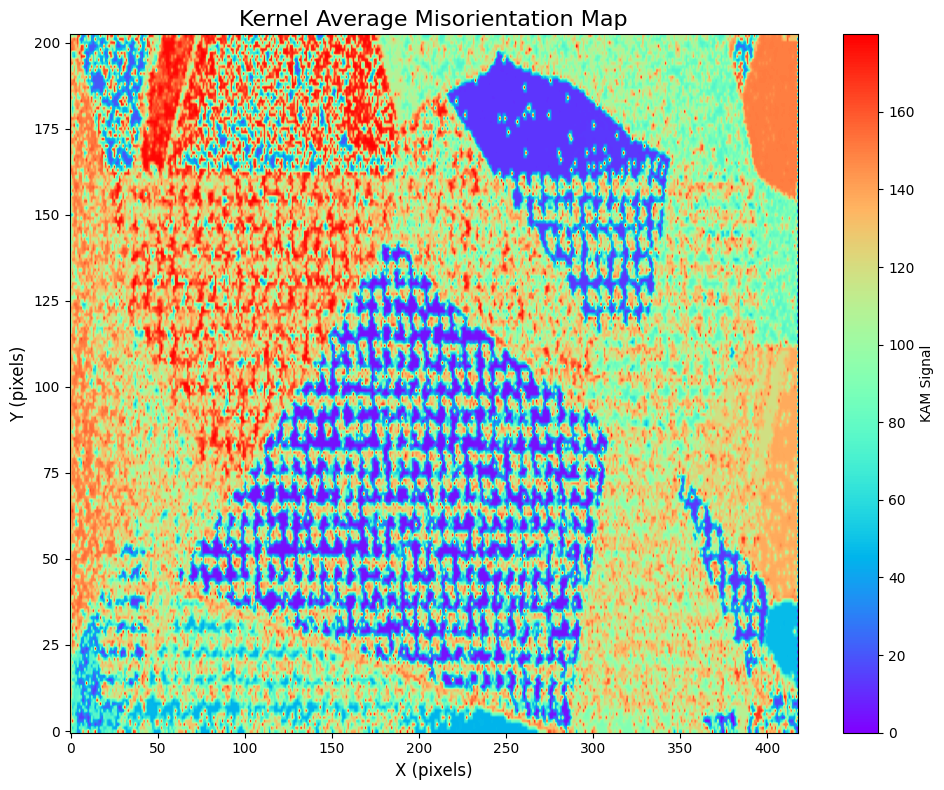

Plot saved as kam_map.png


In [39]:
def calculate_kam(df, NCOLS_ODD, NCOLS_EVEN, NROWS):
    """
    We are calculating the Kernel Average Misorientation (KAM) for each point.
    KAM is a measure of the average misorientation between a point and its neighbors,
    serving as a proxy for local plastic strain.

    This version uses a robust, index-based neighbor search to avoid floating-point
    precision errors that can cause the calculation to fail.
    """
    def euler_to_quaternion(phi1, PHI, phi2):
        rot = R.from_euler('ZXZ', [phi1, PHI, phi2], degrees=False)
        return rot.as_quat()

    def quaternion_to_misorientation(q1, q2):
        # Correct quaternion multiplication
        w1, x1, y1, z1 = q1[3], q1[0], q1[1], q1[2]
        w2, x2, y2, z2 = q2[3], q2[0], q2[1], q2[2]

        mis_q_w = w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2
        mis_q_x = w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2
        mis_q_y = w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2
        mis_q_z = w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2
        
        mis_q = np.array([mis_q_x, mis_q_y, mis_q_z, mis_q_w])
        
        cos_theta_half = np.clip(np.abs(mis_q_w), 0, 1)
        angle = 2 * np.arccos(cos_theta_half) * 180 / np.pi
        return angle

    quaternions = np.array([euler_to_quaternion(row['phi1'], row['PHI'], row['phi2']) for _, row in df.iterrows()])
    kam_values = np.zeros(len(df))

    # Create a 2D map to easily find neighbors
    data_idx_map = np.full((NROWS, NCOLS_ODD), -1, dtype=int)
    current_1d_idx = 0
    for r in range(NROWS):
        num_cols = NCOLS_ODD if r % 2 == 0 else NCOLS_EVEN
        for c in range(num_cols):
            if c < NCOLS_ODD:
                data_idx_map[r, c] = current_1d_idx
            current_1d_idx += 1
            if current_1d_idx >= len(quaternions):
                break
        if current_1d_idx >= len(quaternions):
            break

    # Iterate through each point on the grid and find its neighbors
    for r in range(NROWS):
        num_cols = NCOLS_ODD if r % 2 == 0 else NCOLS_EVEN
        for c in range(num_cols):
            if c < NCOLS_ODD and data_idx_map[r, c] != -1:
                current_1d_idx = data_idx_map[r, c]
                current_quat = quaternions[current_1d_idx]
                neighbor_misorientations = []

                # Define neighbor offsets for a hexagonal grid based on the current row
                neighbor_offsets = [(-1, 0), (1, 0), (0, -1), (0, 1)]
                if r % 2 == 0: # Even rows
                    neighbor_offsets.extend([(-1, -1), (1, -1)])
                else: # Odd rows
                    neighbor_offsets.extend([(-1, 1), (1, 1)])

                for dr, dc in neighbor_offsets:
                    neighbor_r, neighbor_c = r + dr, c + dc
                    
                    if 0 <= neighbor_r < NROWS and 0 <= neighbor_c < NCOLS_ODD:
                        neighbor_idx = data_idx_map[neighbor_r, neighbor_c]
                        if neighbor_idx != -1:
                            neighbor_quat = quaternions[neighbor_idx]
                            misorientation = quaternion_to_misorientation(current_quat, neighbor_quat)
                            neighbor_misorientations.append(misorientation)
                
                if neighbor_misorientations:
                    kam_values[current_1d_idx] = np.mean(neighbor_misorientations)
                else:
                    kam_values[current_1d_idx] = 0

    df['KAM'] = kam_values
    return df

# 5. KAM Map
print("We are now plotting the KAM map to visualize local plastic strain.")
df_with_kam = calculate_kam(df, NCOLS_ODD, NCOLS_EVEN, NROWS)
plot_from_grid_data(df_with_kam, 'KAM', 'Kernel Average Misorientation Map', cm.rainbow, 'kam_map.png', NCOLS_ODD, NCOLS_EVEN, NROWS)

## **6. IQ vs. CI Comparison Plot**
**Input**: The IQ and CI (Confidence Index) values.

**Output**: A scatter plot with CI on the x-axis and IQ on the y-axis.

**Significance**: This diagnostic plot helps to assess the overall quality of the EBSD data. A good dataset will show a positive correlation, where points with a high IQ also have a high CI, confirming that the data is both well-defined and reliably indexed.

We are plotting a comparison of Image Quality (IQ) and Confidence Index (CI) to assess data quality.


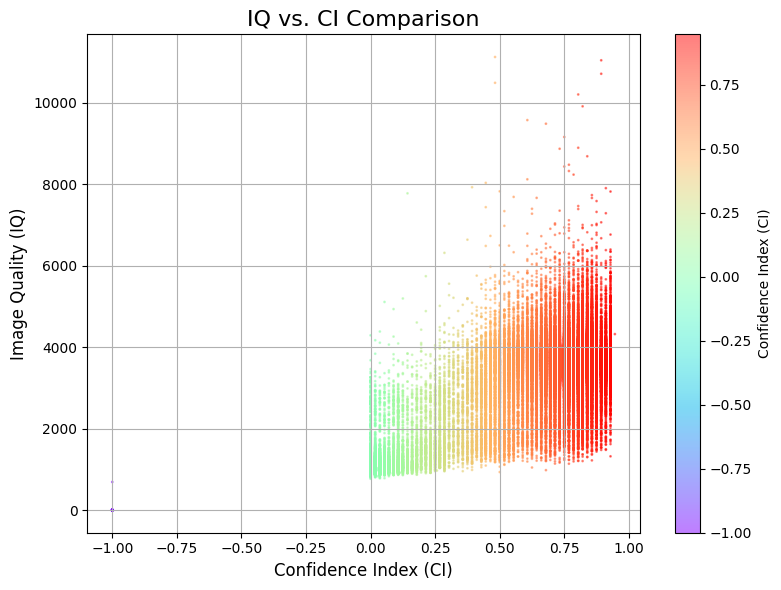

Comparison plot saved as iq_ci_comparison.png


In [40]:
# 6. IQ vs. CI Comparison Plot
print("We are plotting a comparison of Image Quality (IQ) and Confidence Index (CI) to assess data quality.")
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df['CI'], df['IQ'], s=1, c=df['CI'], cmap='rainbow', alpha=0.5)

plt.title('IQ vs. CI Comparison', fontsize=16)
plt.xlabel('Confidence Index (CI)', fontsize=12)
plt.ylabel('Image Quality (IQ)', fontsize=12)
plt.grid(True)
plt.colorbar(scatter, label='Confidence Index (CI)')
plt.tight_layout()
plt.savefig('iq_ci_comparison.png')
plt.show()
print("Comparison plot saved as iq_ci_comparison.png")

!pip install scikit-learn

In [1]:
!pip install scikit-learn

  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB 991.0 kB/s eta 0:00:09
    --------------------------------------- 0.2/8.9 MB 2.5 MB/s eta 0:00:04
   -- ------------------------------------- 0.5/8.9 MB 3.9 MB/s eta 0:00:03
   ---- ----------------------------------- 1.1/8.9 MB 6.1 MB/s eta 0:00:02
   -------- ------------------------------- 1.9/8.9 MB 8.6 MB/s eta 0:00:01
   --------------- ------------------------ 3.4/8.9 MB 12.2 MB/s eta 0:00:01
   -------------------- ------------------- 4.5/8.9 MB 13.1 MB/s eta 0:00:01
   ------------------------- -------------- 5.7/8.9 MB 14.5 MB/s eta 0:00:01
   ------------------------------- -------- 7.1/8.9 MB 16.1 MB/s eta 0:00:01
   ------------------------------------- -- 8.3/8.9 MB 17.2 MB/s eta 0:00:01
   ---------------------------------------- 8.9/8.9 MB 16.2 MB/s eta 0:00:00
   ---------------


[notice] A new release of pip is available: 23.3.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import io
from sklearn.cluster import DBSCAN

# --- 1. Load your data (using the correct method from plots.ipynb) ---
file_path = "ebsd.txt"

with open(file_path, 'r') as file:
    lines = file.readlines()

# Find the end of the header
header_end_index = None
column_headers_line = None
for i, line in enumerate(lines):
    if line.strip() == "# HEADER: End":
        header_end_index = i
    if line.startswith("# COLUMN_HEADERS:"):
        column_headers_line = line

if header_end_index is None or column_headers_line is None:
    raise ValueError("Could not find required header information in the text file.")

# Parse the column headers dynamically from the file
column_headers = column_headers_line.split(":")[1].strip().split(",")
column_headers = [header.strip() for header in column_headers]

# Join only the data lines into a single string
data_string = "".join(lines[header_end_index + 1:])

# Read the data string into pandas
df = pd.read_csv(
    io.StringIO(data_string), 
    sep='\\s+', 
    names=column_headers
)

print(f"Successfully loaded {len(df)} data points using the notebook's method.")


# --- 2. Isolate ALL points belonging to indents ---
# Use the filter to get all "bad" data points (low IQ or low CI)
indent_points_df = df[(df['CI'] <= 0.1) | (df['IQ'] <= 100)].copy()

print(f"Found {len(indent_points_df)} total points belonging to indents.")


# --- 3. Cluster these points into groups (one for each indent) ---
# Get the 'x' and 'y' coordinates for clustering
coordinates = indent_points_df[['x', 'y']]

# Set up DBSCAN
# Your XSTEP from the header is 0.8. We'll set 'eps' (the max distance
# between points in a cluster) to be slightly larger, e.g., 1.5,
# to ensure all points within one indent are grouped together.
# 'min_samples' is the minimum number of points to form a cluster.
db = DBSCAN(eps=1.5, min_samples=20).fit(coordinates)

# Add the cluster labels back to our DataFrame
# (-1 is noise, 0, 1, 2... are the individual indent clusters)
indent_points_df['cluster_label'] = db.labels_


# --- 4. Calculate the Center (Centroid) of Each Cluster ---
# First, remove any "noise" points that DBSCAN found (label -1)
clusters_df = indent_points_df[indent_points_df['cluster_label'] != -1]

# Group by the cluster label and find the mean 'x' and 'y'
# This calculates the center coordinate of each indent.
indent_centers = clusters_df.groupby('cluster_label')[['x', 'y']].mean()


# --- 5. Verification ---
print(f"Successfully identified {len(indent_centers)} indent centers.")
print("The (x, y) coordinates of the first 5 indent centers are:")
print(indent_centers.head())

# You can save these 1000 coordinates to a new file
indent_centers.to_csv('indent_center_coordinates.csv')

Successfully loaded 84753 data points using the notebook's method.
Found 8588 total points belonging to indents.
Successfully identified 0 indent centers.
The (x, y) coordinates of the first 5 indent centers are:
Empty DataFrame
Columns: [x, y]
Index: []


In [5]:
import pandas as pd
import numpy as np
import io
from sklearn.cluster import DBSCAN

# --- 1. Load your data (This part worked perfectly) ---
file_path = "ebsd.txt"
with open(file_path, 'r') as file:
    lines = file.readlines()
header_end_index = None
column_headers_line = None
for i, line in enumerate(lines):
    if line.strip() == "# HEADER: End":
        header_end_index = i
    if line.startswith("# COLUMN_HEADERS:"):
        column_headers_line = line
column_headers = column_headers_line.split(":")[1].strip().split(",")
column_headers = [header.strip() for header in column_headers]
data_string = "".join(lines[header_end_index + 1:])
df = pd.read_csv(
    io.StringIO(data_string), 
    sep='\\s+', 
    names=column_headers
)
print(f"Successfully loaded {len(df)} data points.")

# --- 2. Isolate ALL points belonging to indents (This also worked) ---
indent_points_df = df[(df['CI'] <= 0.1) | (df['IQ'] <= 100)].copy()
print(f"Found {len(indent_points_df)} total points belonging to indents.")

# --- 3. Cluster these points (THE CORRECTED STEP) ---
coordinates = indent_points_df[['x', 'y']]

# *** PARAMETER CHANGE HERE ***
# We are lowering min_samples from 20 to 5, because the
# data shows our indents are small (~8-9 points each).
# We keep eps=1.5 as it is a good radius based on your XSTEP.
db = DBSCAN(eps=1.5, min_samples=5).fit(coordinates)

indent_points_df['cluster_label'] = db.labels_

# --- 4. Calculate the Center (Centroid) of Each Cluster ---
clusters_df = indent_points_df[indent_points_df['cluster_label'] != -1]
indent_centers = clusters_df.groupby('cluster_label')[['x', 'y']].mean()

# --- 5. Verification ---
num_centers = len(indent_centers)
print(f"Successfully identified {num_centers} indent centers.")

if num_centers > 0:
    print("The (x, y) coordinates of the first 5 indent centers are:")
    print(indent_centers.head())
else:
    print("No clusters found. Try Solution 2 or try lowering 'min_samples' even more (e.g., to 3).")

Successfully loaded 84753 data points.
Found 8588 total points belonging to indents.
Successfully identified 970 indent centers.
The (x, y) coordinates of the first 5 indent centers are:
                        x         y
cluster_label                      
0              303.085713  6.136406
1              242.327274  6.802233
2              186.900002  7.101405
3              236.000000  7.082160
4              248.171430  7.027174


In [9]:
import pandas as pd
import numpy as np
import io
from sklearn.cluster import DBSCAN

# --- 1. Load your data (using the correct method from plots.ipynb) ---
file_path = "ebsd.txt"

try:
    with open(file_path, 'r') as file:
        lines = file.readlines()

    header_end_index = None
    column_headers_line = None
    for i, line in enumerate(lines):
        if line.strip() == "# HEADER: End":
            header_end_index = i
        if line.startswith("# COLUMN_HEADERS:"):
            column_headers_line = line

    if header_end_index is None or column_headers_line is None:
        raise ValueError("Could not find required header information in the text file.")

    column_headers = column_headers_line.split(":")[1].strip().split(",")
    column_headers = [header.strip() for header in column_headers]
    data_string = "".join(lines[header_end_index + 1:])
    df = pd.read_csv(
        io.StringIO(data_string), 
        sep='\\s+', 
        names=column_headers
    )
    print(f"Successfully loaded {len(df)} data points.")

    # --- 2. Isolate ALL points belonging to indents (using IQ/CI filter) ---
    indent_points_df = df[(df['CI'] <= 0.1) | (df['IQ'] <= 100)].copy()
    print(f"Found {len(indent_points_df)} total points belonging to indents.")

    # --- 3. Cluster these points (Tuned min_samples) ---
    coordinates = indent_points_df[['x', 'y']]

    # We had 970 centers with min_samples=5.
    # We will lower min_samples to 3 to capture the small clusters.
    db = DBSCAN(eps=1.5, min_samples=3).fit(coordinates)
    
    indent_points_df['cluster_label'] = db.labels_

    # --- 4. Calculate the Center (Centroid) of Each Cluster ---
    clusters_df = indent_points_df[indent_points_df['cluster_label'] != -1]
    indent_centers = clusters_df.groupby('cluster_label')[['x', 'y']].mean()

    # --- 5. Verification ---
    num_centers = len(indent_centers)
    print(f"Successfully identified {num_centers} indent centers.")

    if num_centers > 0:
        print("The (x, y) coordinates of the first 5 indent centers are:")
        print(indent_centers.head())
        
        # Save the coordinates to a file
        indent_centers.to_csv('indent_center_coordinates.csv')
        print(f"Saved {num_centers} indent coordinates to 'indent_center_coordinates.csv'")
    else:
        print("No clusters found.")

except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please upload the file.")
except Exception as e:
    print(f"An error occurred: {e}")

Successfully loaded 84753 data points.
Found 8588 total points belonging to indents.
Successfully identified 1009 indent centers.
The (x, y) coordinates of the first 5 indent centers are:
                        x         y
cluster_label                      
0              298.400003  4.156920
1              302.986666  6.004440
2              242.327274  6.802233
3              266.533333  6.812730
4              290.839999  6.720354
Saved 1009 indent coordinates to 'indent_center_coordinates.csv'


Loading data...
Successfully loaded 84753 data points.
Found 8588 total points belonging to indents.
Running clustering...
Successfully identified 1009 indent centers.
Saved 1009 indent coordinates to 'indent_center_coordinates.csv'
Generating cluster plot...
Successfully saved cluster visualization to 'indent_cluster_plot.png'


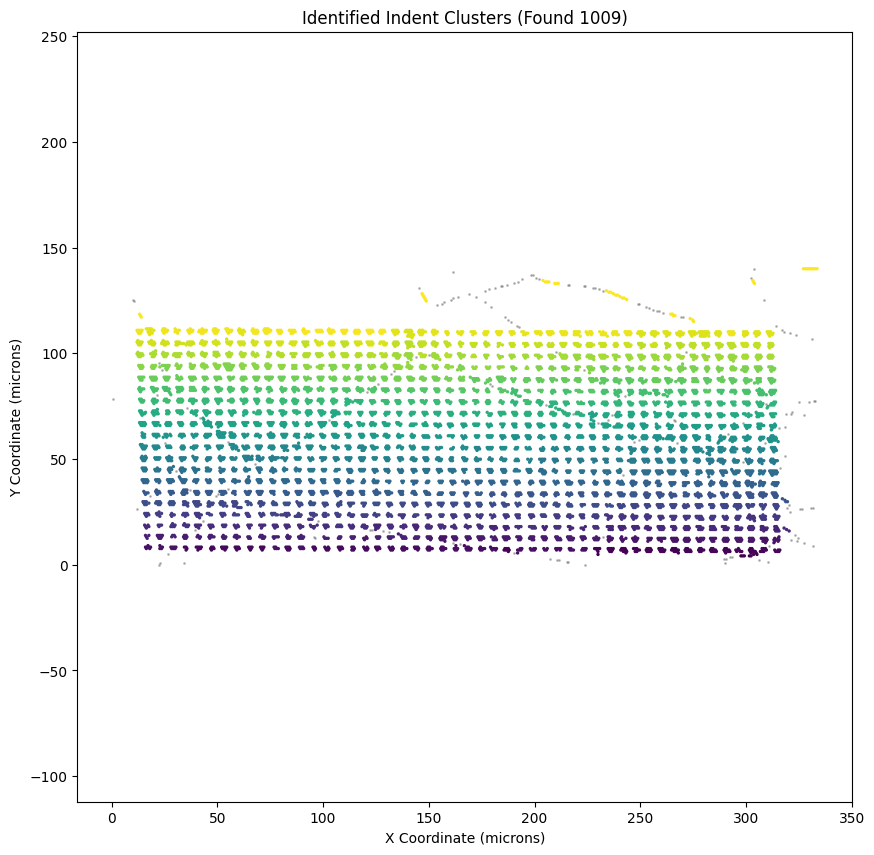

In [10]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# --- 1. Load your data (This part worked) ---
file_path = "ebsd.txt"

print("Loading data...")
with open(file_path, 'r') as file:
    lines = file.readlines()

header_end_index = None
column_headers_line = None
for i, line in enumerate(lines):
    if line.strip() == "# HEADER: End":
        header_end_index = i
    if line.startswith("# COLUMN_HEADERS:"):
        column_headers_line = line

if header_end_index is None or column_headers_line is None:
    raise ValueError("Could not find required header information in the text file.")

column_headers = column_headers_line.split(":")[1].strip().split(",")
column_headers = [header.strip() for header in column_headers]
data_string = "".join(lines[header_end_index + 1:])
df = pd.read_csv(
    io.StringIO(data_string), 
    sep='\\s+', 
    names=column_headers
)
print(f"Successfully loaded {len(df)} data points.")

# --- 2. Isolate ALL points belonging to indents (using IQ/CI filter) ---
indent_points_df = df[(df['CI'] <= 0.1) | (df['IQ'] <= 100)].copy()
print(f"Found {len(indent_points_df)} total points belonging to indents.")

# --- 3. Cluster these points (Tuned min_samples=3) ---
print("Running clustering...")
coordinates = indent_points_df[['x', 'y']]
db = DBSCAN(eps=1.5, min_samples=3).fit(coordinates)
indent_points_df['cluster_label'] = db.labels_

# --- 4. Calculate the Center (Centroid) of Each Cluster ---
clusters_df = indent_points_df[indent_points_df['cluster_label'] != -1]
indent_centers = clusters_df.groupby('cluster_label')[['x', 'y']].mean()
num_centers = len(indent_centers)
print(f"Successfully identified {num_centers} indent centers.")

# --- 5. Save the coordinates (Same as before) ---
if num_centers > 0:
    indent_centers.to_csv('indent_center_coordinates.csv')
    print(f"Saved {num_centers} indent coordinates to 'indent_center_coordinates.csv'")

# --- 6. NEW: Create and save the cluster plot ---
print("Generating cluster plot...")
try:
    # Separate the noise points from the clustered indent points
    plot_clusters_df = indent_points_df[indent_points_df['cluster_label'] != -1]
    plot_noise_df = indent_points_df[indent_points_df['cluster_label'] == -1]
    
    plt.figure(figsize=(10, 10))
    
    # Plot noise points first in gray
    plt.scatter(plot_noise_df['x'], plot_noise_df['y'], 
                color='gray', s=1, alpha=0.5, label='Noise')
    
    # Plot the identified clusters (indents)
    # We use a colormap to give each cluster a different color
    plt.scatter(plot_clusters_df['x'], plot_clusters_df['y'], 
                c=plot_clusters_df['cluster_label'], 
                cmap='viridis', s=2, label='Indents')
    
    plt.xlabel('X Coordinate (microns)')
    plt.ylabel('Y Coordinate (microns)')
    plt.title(f'Identified Indent Clusters (Found {num_centers})')
    plt.axis('equal') # Ensures x and y axes have the same scale
    
    # Save the plot
    plot_filename = 'indent_cluster_plot.png'
    plt.savefig(plot_filename, dpi=300)
    
    print(f"Successfully saved cluster visualization to '{plot_filename}'")

except Exception as e:
    print(f"An error occurred during plotting: {e}")

Loading data...
Successfully loaded 84753 data points.
Initially found 8588 total points belonging to indents.
After bounding box filter, 8480 points remain for clustering.
Running clustering on filtered points...
Successfully identified 1000 indent centers.
Generating cluster plot...


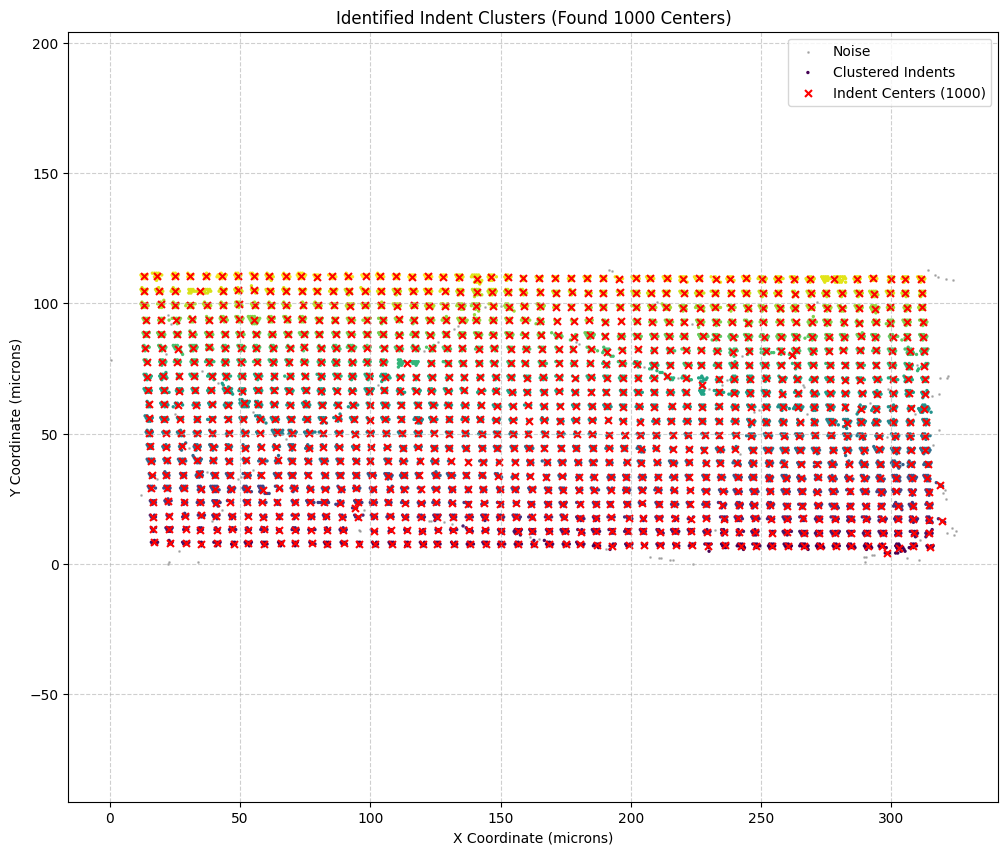

Success! Exactly 1000 centers found.


In [ ]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
import sys

# --- 1. Load your data (using the correct method from plots.ipynb) ---
file_path = "ebsd.txt"

print("Loading data...")
try:
    with open(file_path, 'r') as file:
        lines = file.readlines()
except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found.")
    print("Please make sure the file is in the same directory as your script.")
    sys.exit() # Exit if file not found
except Exception as e:
    print(f"An error occurred loading the file: {e}")
    sys.exit()

header_end_index = None
column_headers_line = None
for i, line in enumerate(lines):
    if line.strip() == "# HEADER: End":
        header_end_index = i
    if line.startswith("# COLUMN_HEADERS:"):
        column_headers_line = line

if header_end_index is None or column_headers_line is None:
    print("Error: Could not find required header information in the text file.")
    sys.exit()

# Parse the column headers dynamically from the file
column_headers = column_headers_line.split(":")[1].strip().split(",")
column_headers = [header.strip() for header in column_headers]

# Join only the data lines into a single string
data_string = "".join(lines[header_end_index + 1:])

# Read the data string into pandas
df = pd.read_csv(
    io.StringIO(data_string), 
    sep='\\s+', 
    names=column_headers
)
print(f"Successfully loaded {len(df)} data points.")

# --- 2. Isolate ALL points belonging to indents (using IQ/CI filter) ---
indent_points_df_initial = df[(df['CI'] <= 0.1) | (df['IQ'] <= 100)].copy()
print(f"Initially found {len(indent_points_df_initial)} total points belonging to indents.")

# --- 3. Apply Bounding Box Filter to remove boundary clusters ---
# Define coordinates based on the visual inspection of the plot
x_min_boundary = -5   # Slightly below 0 to capture all start points
x_max_boundary = 325  # Cut off noise on the right
y_min_boundary = -5   # Slightly below 0
y_max_boundary = 115  # Cut off noise above the main grid

# *** THIS IS THE CORRECTED FILTER ***
# It now uses 'indent_points_df_initial' for all conditions.
indent_points_df_filtered = indent_points_df_initial[
    (indent_points_df_initial['x'] > x_min_boundary) & 
    (indent_points_df_initial['x'] < x_max_boundary) &
    (indent_points_df_initial['y'] > y_min_boundary) & 
    (indent_points_df_initial['y'] < y_max_boundary)
].copy()

print(f"After bounding box filter, {len(indent_points_df_filtered)} points remain for clustering.")


# --- 4. DBSCAN Clustering on the filtered points ---
print("Running clustering on filtered points...")
coordinates = indent_points_df_filtered[['x', 'y']]

# Parameters that gave us 1009 previously, now applied to cleaner data
db = DBSCAN(eps=1.5, min_samples=3).fit(coordinates)
indent_points_df_filtered['cluster_label'] = db.labels_

# --- 5. Calculate the Center (Centroid) of Each Cluster ---
clusters_df = indent_points_df_filtered[indent_points_df_filtered['cluster_label'] != -1]
indent_centers = clusters_df.groupby('cluster_label')[['x', 'y']].mean()
num_centers = len(indent_centers)
print(f"Successfully identified {num_centers} indent centers.")

# --- 6. Plot the clusters (without saving) ---
print("Generating cluster plot...")
plt.figure(figsize=(12, 10))

# Separate noise and clustered points for plotting
plot_clusters_df = indent_points_df_filtered[indent_points_df_filtered['cluster_label'] != -1]
plot_noise_df = indent_points_df_filtered[indent_points_df_filtered['cluster_label'] == -1]

# Plot noise points first in gray
plt.scatter(plot_noise_df['x'], plot_noise_df['y'], 
            color='gray', s=1, alpha=0.5, label='Noise')

# Plot the identified clusters (indents)
plt.scatter(plot_clusters_df['x'], plot_clusters_df['y'], 
            c=plot_clusters_df['cluster_label'], 
            cmap='viridis', s=2, label='Clustered Indents')

# Plot the calculated centroids as larger red markers
plt.scatter(indent_centers['x'], indent_centers['y'], 
            color='red', marker='x', s=25, linewidth=1.5, label=f'Indent Centers ({num_centers})')


plt.xlabel('X Coordinate (microns)')
plt.ylabel('Y Coordinate (microns)')
plt.ylim(-30,130)
plt.title(f'Identified Indent Clusters (Found {num_centers} Centers)')
plt.axis('equal') # Ensures x and y axes have the same scale
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show() # This will display the plot in your notebook/environment

if num_centers == 1000:
    print("Success! Exactly 1000 centers found.")
    # As requested, not saving yet.
    # indent_centers.to_csv('final_1000_indent_coordinates.csv')
else:
    print(f"Result: {num_centers}. Not exactly 1000.")
    print("Review the plot and adjust the x/y_max_boundary values if needed.")

--- Processing NanoIndenter File for Plotting (Corrected Parser) ---
Successfully loaded 633955 total nano data points.

--- Coordinate Bounds Check ---
Pos X: Min=22846.946, Max=22847.713, Unique Values=5675
Pos Y: Min=-832.004, Max=-537.89958, Unique Values=22340

Found 999 unique indent locations to plot.
Generating plot of indent locations...


(22847.1472, 22847.7368, -846.66825, -523.24075)

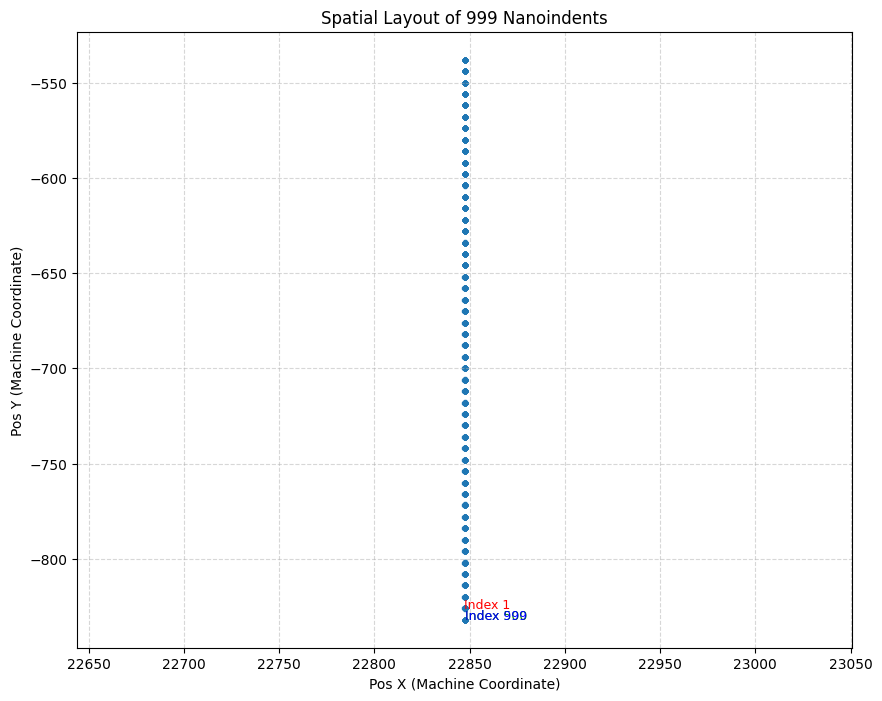

In [20]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
import re
import sys

# --- Configuration ---
nano_file_path = "nano.txt" # Assumes file is in the same directory

print("--- Processing NanoIndenter File for Plotting (Corrected Parser) ---")

try:
    with open(nano_file_path, 'r') as file:
        nano_lines = file.readlines()
except FileNotFoundError:
    print(f"Error: The file '{nano_file_path}' was not found.")
    print("Please make sure it's in the same directory as your script.")
    sys.exit()
except Exception as e:
    print(f"An error occurred loading the file: {e}")
    sys.exit()

# --- STEP 1: Find Header and Parse It Correctly ---
header_index = -1
units_index = -1
separator_index = -1
nano_data_start_index = -1

# Find header line (e.g., "// ... Index ... Phase ... Pos X ...")
for i, line in enumerate(nano_lines):
    if line.strip().startswith("//") and "Index" in line and "Phase" in line and "Pos X" in line:
        header_index = i
        break

if header_index == -1:
    print("Error: Could not find the main header line (e.g., '// Index Phase ...')")
    sys.exit()

# *** THIS IS THE CORRECTED PART ***
# Get the actual header line from the file
nano_header_line_raw = nano_lines[header_index]
# Clean it
clean_header = nano_header_line_raw.replace("//", "").strip()
# Parse it with regex to split on 2+ spaces, keeping "Pos X" together
nano_column_headers = re.split(r'\s{2,}', clean_header)
# --- End of Correction ---

# --- STEP 2: Find Data and Load (Robust Method) ---
# Find units line (must be after header, e.g., "// [#] [#] [um] ...")
for i, line in enumerate(nano_lines[header_index + 1:], start=header_index + 1):
    if line.strip().startswith("//") and "[#]" in line and "[um]" in line:
        units_index = i
        break
        
if units_index == -1:
    print("Error: Could not find the units line (e.g., '// [#] [#] [um] ...')")
    sys.exit()

# Find separator line (must be after units, e.g., "// ===...")
for i, line in enumerate(nano_lines[units_index + 1:], start=units_index + 1):
    if line.strip().startswith("// ==="):
        separator_index = i
        nano_data_start_index = i + 1 # Data starts on the next line
        break

if nano_data_start_index == -1:
    print("Error: Could not find the final '=== separator line before the data.")
    sys.exit()

# Filter out all comment/separator/empty lines from the data block
data_lines = []
for line in nano_lines[nano_data_start_index:]:
    if not line.startswith("//") and not line.startswith("=") and line.strip():
        data_lines.append(line)

nano_data_string = "".join(data_lines)

if not nano_data_string:
    print("Error: No data was found after the header.")
    sys.exit()

# Load all nano data points into one large DataFrame
try:
    nano_df = pd.read_csv(
        io.StringIO(nano_data_string),
        sep='\\s+',
        names=nano_column_headers
    )
    print(f"Successfully loaded {len(nano_df)} total nano data points.")
except ValueError as e:
    print(f"An error occurred during CSV parsing: {e}")
    print("This can happen if the number of detected columns does not match the data.")
    print("Detected columns:", nano_column_headers)
    sys.exit()


# --- STEP 3: Check Bounds (Your Request) ---
print("\n--- Coordinate Bounds Check ---")
try:
    x_min, x_max = nano_df['Pos X'].min(), nano_df['Pos X'].max()
    y_min, y_max = nano_df['Pos Y'].min(), nano_df['Pos Y'].max()
    x_unique = nano_df['Pos X'].nunique()
    y_unique = nano_df['Pos Y'].nunique()

    print(f"Pos X: Min={x_min}, Max={x_max}, Unique Values={x_unique}")
    print(f"Pos Y: Min={y_min}, Max={y_max}, Unique Values={y_unique}")

    if x_unique == 1:
        print("\nWARNING: 'Pos X' has only 1 unique value. Plot will be a vertical line.")
    if y_unique == 1:
        print("\nWARNING: 'Pos Y' has only 1 unique value. Plot will be a horizontal line.")

except KeyError as e:
    print(f"Error: Column {e} not found.")
    print("This means the regex header parsing failed. Review the header logic.")
    print("Parsed columns:", nano_column_headers)
    sys.exit()
except Exception as e:
    print(f"An error occurred during bounds check: {e}")
    sys.exit()


# --- STEP 4: Get One Point Per Indent Index ---
# Group by 'Index' and get the first (Pos X, Pos Y) pair for each one
indent_locations = nano_df.groupby('Index')[['Pos X', 'Pos Y']].first().reset_index()

num_indents = len(indent_locations)
print(f"\nFound {num_indents} unique indent locations to plot.")

# --- STEP 5: Plot the Indent Locations ---
print("Generating plot of indent locations...")
plt.figure(figsize=(10, 8))
plt.scatter(indent_locations['Pos X'], indent_locations['Pos Y'], alpha=0.6, s=10)

# --- Add Annotations for Context ---
if num_indents > 0:
    first_point = indent_locations.iloc[0]
    middle_point_index = int(num_indents / 2)
    middle_point = indent_locations.iloc[middle_point_index]
    last_point = indent_locations.iloc[-1]

    plt.text(first_point['Pos X'], first_point['Pos Y'], 
             f"Index {first_point['Index']:.0f}", color='red', fontsize=9)
    plt.text(middle_point['Pos X'], middle_point['Pos Y'], 
             f"Index {middle_point['Index']:.0f}", color='green', fontsize=9)
    plt.text(last_point['Pos X'], last_point['Pos Y'], 
             f"Index {last_point['Index']:.0f}", color='blue', fontsize=9)

plt.xlabel('Pos X (Machine Coordinate)')
plt.ylabel('Pos Y (Machine Coordinate)')
plt.title(f'Spatial Layout of {num_indents} Nanoindents')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal') # Use equal scaling

# plot_filename = 'nano_indent_layout_plot.png'
# plt.savefig(plot_filename)
# print(f"Successfully saved plot to '{plot_filename}'")

--- Processing NanoIndenter File (Plotting Y vs Z) ---
Successfully loaded 633955 total nano data points.

--- Coordinate Bounds Check ---
Pos X: Unique Values=5675
Pos Y: Min=-832.00, Max=-537.90, Unique Values=22340
Pos Z: Min=5583.94, Max=5697.97, Unique Values=7491

Found 999 unique indent locations to plot.
Generating plot of indent locations (Y vs Z)...
Successfully saved plot to 'nano_indent_layout_plot_Y_vs_Z.png'


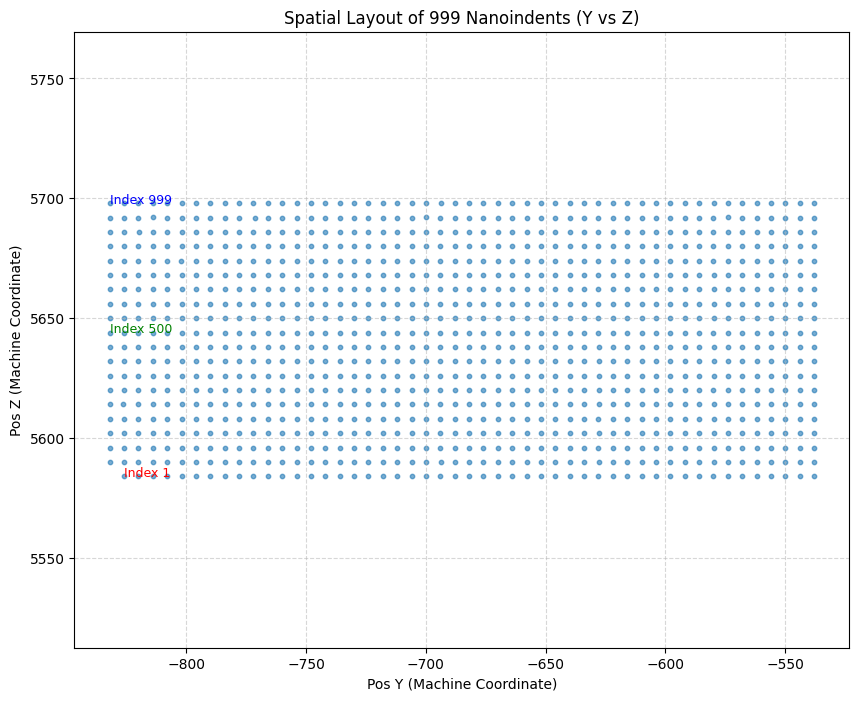

In [22]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
import re
import sys

# --- Configuration ---
nano_file_path = "nano.txt" # Assumes file is in the same directory

print("--- Processing NanoIndenter File (Plotting Y vs Z) ---")

try:
    with open(nano_file_path, 'r') as file:
        nano_lines = file.readlines()
except FileNotFoundError:
    print(f"Error: The file '{nano_file_path}' was not found.")
    print("Please make sure it's in the same directory as your script.")
    sys.exit()
except Exception as e:
    print(f"An error occurred loading the file: {e}")
    sys.exit()

# --- STEP 1: Find Header and Parse It Correctly (Fixes ValueError) ---
header_index = -1
units_index = -1
separator_index = -1
nano_data_start_index = -1

# Find header line (e.g., "// ... Index ... Phase ... Pos X ...")
for i, line in enumerate(nano_lines):
    if line.strip().startswith("//") and "Index" in line and "Phase" in line and "Pos X" in line:
        header_index = i
        break

if header_index == -1:
    print("Error: Could not find the main header line (e.g., '// Index Phase ...')")
    sys.exit()

# Get the actual header line from the file
nano_header_line_raw = nano_lines[header_index]
# Clean it
clean_header = nano_header_line_raw.replace("//", "").strip()
# Parse it with regex to split on 2+ spaces, keeping "Pos Y", "Pos Z" etc. together
nano_column_headers = re.split(r'\s{2,}', clean_header)

# --- STEP 2: Find Data and Load (Robust Method) ---
# Find units line (must be after header, e.g., "// [#] [#] [um] ...")
for i, line in enumerate(nano_lines[header_index + 1:], start=header_index + 1):
    if line.strip().startswith("//") and "[#]" in line and "[um]" in line:
        units_index = i
        break
        
if units_index == -1:
    print("Error: Could not find the units line (e.g., '// [#] [#] [um] ...')")
    sys.exit()

# Find separator line (must be after units, e.g., "// ===...")
for i, line in enumerate(nano_lines[units_index + 1:], start=units_index + 1):
    if line.strip().startswith("// ==="):
        separator_index = i
        nano_data_start_index = i + 1 # Data starts on the next line
        break

if nano_data_start_index == -1:
    print("Error: Could not find the final '=== separator line before the data.")
    sys.exit()

# Filter out all comment/separator/empty lines from the data block
data_lines = []
for line in nano_lines[nano_data_start_index:]:
    if not line.startswith("//") and not line.startswith("=") and line.strip():
        data_lines.append(line)
nano_data_string = "".join(data_lines)

# Load all nano data points into one large DataFrame
try:
    nano_df = pd.read_csv(
        io.StringIO(nano_data_string),
        sep='\\s+',
        names=nano_column_headers
    )
    print(f"Successfully loaded {len(nano_df)} total nano data points.")
except ValueError as e:
    print(f"An error occurred during CSV parsing: {e}")
    print("This can happen if the number of detected columns does not match the data.")
    print("Detected columns:", nano_column_headers)
    sys.exit()


# --- STEP 3: Check Bounds (Now including Pos Z) ---
print("\n--- Coordinate Bounds Check ---")
try:
    x_unique = nano_df['Pos X'].nunique()
    y_unique = nano_df['Pos Y'].nunique()
    z_unique = nano_df['Pos Z'].nunique()

    print(f"Pos X: Unique Values={x_unique}")
    print(f"Pos Y: Min={nano_df['Pos Y'].min():.2f}, Max={nano_df['Pos Y'].max():.2f}, Unique Values={y_unique}")
    print(f"Pos Z: Min={nano_df['Pos Z'].min():.2f}, Max={nano_df['Pos Z'].max():.2f}, Unique Values={z_unique}")

    if x_unique == 1:
        print("Confirmed: 'Pos X' is constant.")
    
except KeyError as e:
    print(f"Error: Column {e} not found.")
    print("Parsed columns:", nano_column_headers)
    sys.exit()


# --- STEP 4: Get One Point Per Indent Index (Using Y and Z) ---
# Group by 'Index' and get the first (Pos Y, Pos Z) pair for each one
indent_locations = nano_df.groupby('Index')[['Pos Y', 'Pos Z']].first().reset_index()

num_indents = len(indent_locations)
print(f"\nFound {num_indents} unique indent locations to plot.")

# --- STEP 5: Plot the Indent Locations (Y vs Z) ---
print("Generating plot of indent locations (Y vs Z)...")
plt.figure(figsize=(10, 8))
plt.scatter(indent_locations['Pos Y'], indent_locations['Pos Z'], alpha=0.6, s=10)

# --- Add Annotations for Context ---
if num_indents > 0:
    first_point = indent_locations.iloc[0]
    middle_point_index = int(num_indents / 2)
    middle_point = indent_locations.iloc[middle_point_index]
    last_point = indent_locations.iloc[-1]

    plt.text(first_point['Pos Y'], first_point['Pos Z'], 
             f"Index {first_point['Index']:.0f}", color='red', fontsize=9)
    plt.text(middle_point['Pos Y'], middle_point['Pos Z'], 
             f"Index {middle_point['Index']:.0f}", color='green', fontsize=9)
    plt.text(last_point['Pos Y'], last_point['Pos Z'], 
             f"Index {last_point['Index']:.0f}", color='blue', fontsize=9)

plt.xlabel('Pos Y (Machine Coordinate)')
plt.ylabel('Pos Z (Machine Coordinate)')
plt.title(f'Spatial Layout of {num_indents} Nanoindents (Y vs Z)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal') # Use equal scaling

plot_filename = 'nano_indent_layout_plot_Y_vs_Z.png'
plt.savefig(plot_filename)
print(f"Successfully saved plot to '{plot_filename}'")